In [109]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd
import seaborn as sns
import re,nltk,json, pickle
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import regularizers
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import LSTM,GRU
from tensorflow.keras.models import load_model
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
np.random.seed(42)
class color: # Text style
   PURPLE = '\033[95m'
   CYAN = '\033[96m'
   DARKCYAN = '\033[36m'
   BLUE = '\033[94m'
   GREEN = '\033[92m'
   YELLOW = '\033[93m'
   RED = '\033[91m'
   BOLD = '\033[1m'
   UNDERLINE = '\033[4m'
   END = '\033[0m'
# Warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [111]:
import tensorflow as tf
print(tf.__version__)

2.13.0


In [112]:
file_path = '/content/drive/MyDrive/Bkash Fraud paper/Bkash Fraud Analysis.csv'

In [113]:
df = pd.read_csv(file_path,encoding='UTF-16',sep='\t')
df.head(3)

,Comments,Label
0,জব এর কথা বলে আমার থেকে ১২০০ টাকা নিয়েছে। ৫০০ ...,Fraud
1,বৃত্তির কথা বলে আমার থেকে আজকে ৩৫০০০ হাজার টাক...,Fraud
2,ভাই আমার পরিচিতো এক জন মহিলা বিকাশ ভেরিফাই কোট...,Fraud


# **Data Preparation and Cleaning**

In [114]:
s_word =pd.read_excel('/content/drive/MyDrive/code file/stopwords_bangla.xlsx')
stop = s_word['words'].tolist()

display(s_word)

,Unnamed: 0,words
0,0,অই
1,1,অগত্যা
2,2,অত: পর
3,3,অতএব
4,4,অথচ
...,...,...
727,727,হয়েই
728,728,হয়েছিল
729,729,হয়েছে
730,730,হয়েছেন


In [115]:
def process_conversations(Conversation):
    stp = open('/content/drive/MyDrive/code file/stopword-bn.txt','r',encoding="utf8").read().split()
    result = Conversation.split()
    Conversation = [word.strip() for word in result if word not in stp ]
    Conversation =" ".join(Conversation)
    Conversation = re.sub('[^\u0980-\u09FF]',' ',str(Conversation))
    return Conversation

In [116]:
# Data cleaning function
import re
def process_comments(Comments):
    Comments = re.sub('[^\u0980-\u09FF]',' ',str(Comments)) #removing unnecessary punctuation
    return Comments

In [117]:
# Apply the function into the dataframe
df['cleaned'] = df['Comments'].apply(process_comments)

# print some cleaned reviews from the dataset
sample_data = [16,17,26]
for i in sample_data:
     print('Original:\n',df.Comments[i],'\nCleaned:\n',
           df.cleaned[i],'\n','Label:-- ',df.Label[i],'\n')

Original:
 আমি বিকাশে ২৪০০০ টাকা প্রতারিত হয়েছি কিন্তু জেনে আমারও প্রতারিত হয়েছি ওই নাম্বারে ফোন দেওয়ার ফলে বলছে যে টাকা নাকি উঠিয়ে নিয়ে গেছে দুজন লোক এখন কি করবো 
Cleaned:
 আমি বিকাশে ২৪০০০ টাকা প্রতারিত হয়েছি কিন্তু জেনে আমারও প্রতারিত হয়েছি ওই নাম্বারে ফোন দেওয়ার ফলে বলছে যে টাকা নাকি উঠিয়ে নিয়ে গেছে দুজন লোক এখন কি করবো 
 Label:--  Fraud 

Original:
 আমার আব্বুর বিকাশ থেকে গতকাল রাতে ৪০০০ হাজার একশত ৬০ টাকা নিয়েছে 
Cleaned:
 আমার আব্বুর বিকাশ থেকে গতকাল রাতে ৪০০০ হাজার একশত ৬০ টাকা নিয়েছে 
 Label:--  Fraud 

Original:
 আমার সাথে আজ প্রতারণা হয়েছে আমার ১৪০৬৫ টাকা নিয়েছে 
Cleaned:
 আমার সাথে আজ প্রতারণা হয়েছে আমার ১৪০৬৫ টাকা নিয়েছে 
 Label:--  Fraud 



In [118]:
### Removing Small Texts

df['length'] = df['cleaned'].apply(lambda x:len(x.split()))

dataset = df.loc[df.length>3]
dataset = dataset.reset_index(drop = True)
print("After Cleaning:","\nRemoved {} Small conversations".format(len(df)-len(dataset)),
      "\nTotal conversations:",len(dataset))

dataset['no_char'] = df['cleaned'].apply(lambda cleaned: len(cleaned))

After Cleaning: 
Removed 0 Small conversations 
Total conversations: 520


# **Document Length Distribution**

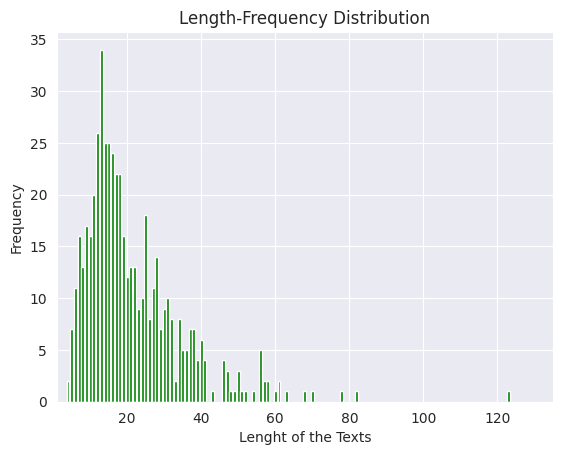

Maximum Length of a commnets: 123
Minimum Length of a commnets: 4
Average Length of a commnets: 21.0


In [119]:
# Calculate the Review of each of the Review
df['CommentLength'] = df.cleaned.apply(lambda x:len(x.split()))
frequency = dict()
for i in df.CommentLength:
    frequency[i] = frequency.get(i, 0)+1

plt.bar(frequency.keys(), frequency.values(), color ="g")
plt.xlim(1, 135)
# in this notbook color is not working but it should work.
plt.xlabel('Lenght of the Texts')
plt.ylabel('Frequency')
plt.title('Length-Frequency Distribution')
plt.show()
print(f"Maximum Length of a commnets: {max(df.CommentLength)}")
print(f"Minimum Length of a commnets: {min(df.CommentLength)}")
print(f"Average Length of a commnets: {round(np.mean(df.CommentLength),0)}")

**Stemming**

In [120]:
!pip install bangla-stemmer
from bangla_stemmer.stemmer import stemmer
## stemmer function
def stem_text (x):
  stmr = stemmer.BanglaStemmer()
  words=x.split(' ')
  stm = stmr.stem(words)
  words=(' ').join(stm)
  return words

In [121]:
df['stemming']=df['cleaned'].apply(stem_text)

Streaming output truncated to the last 5000 lines.
applied second rules..
applied second rules..
applied first rules..
applied first rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied second rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied second rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied first rules..
applied fourth rules..
applied first rules..
applied second rules..
applied first rules..
applied second rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied third rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied first ru

In [122]:
df.head(3)

,Comments,Label,cleaned,length,CommentLength,stemming
0,জব এর কথা বলে আমার থেকে ১২০০ টাকা নিয়েছে। ৫০০ ...,Fraud,জব এর কথা বলে আমার থেকে ১২০০ টাকা নিয়েছে ৫০০ ...,19,19,জব এর কথা বলে আম থেক ১২০০ টাকা নিয় ৫০০ টাকা ই...
1,বৃত্তির কথা বলে আমার থেকে আজকে ৩৫০০০ হাজার টাক...,Fraud,বৃত্তির কথা বলে আমার থেকে আজকে ৩৫০০০ হাজার টাক...,16,16,বৃত্তির কথা বলে আম থেক আজ ৩৫০০০ হাজা টাকা নিয়ে...
2,ভাই আমার পরিচিতো এক জন মহিলা বিকাশ ভেরিফাই কোট...,Fraud,ভাই আমার পরিচিতো এক জন মহিলা বিকাশ ভেরিফাই কোট...,25,25,ভাই আম পরিচি এক জন মহিলা বিকাশ ভেরিফা কোট টি ব...


In [123]:
df.drop(["Comments", "length", "CommentLength"], axis = 1, inplace=True)

In [124]:
df.head(3)

,Label,cleaned,stemming
0,Fraud,জব এর কথা বলে আমার থেকে ১২০০ টাকা নিয়েছে ৫০০ ...,জব এর কথা বলে আম থেক ১২০০ টাকা নিয় ৫০০ টাকা ই...
1,Fraud,বৃত্তির কথা বলে আমার থেকে আজকে ৩৫০০০ হাজার টাক...,বৃত্তির কথা বলে আম থেক আজ ৩৫০০০ হাজা টাকা নিয়ে...
2,Fraud,ভাই আমার পরিচিতো এক জন মহিলা বিকাশ ভেরিফাই কোট...,ভাই আম পরিচি এক জন মহিলা বিকাশ ভেরিফা কোট টি ব...


In [125]:
# data summary

def data_summary(df):
    reviews = []
    words = []
    u_words = []
    total_u_words = [word.strip().lower() for t in list(df.cleaned) for word in t.strip().split()]
    class_label= [k for k,v in df.Label.value_counts().to_dict().items()]
  # find word list
    for label in class_label:
        word_list = [word.strip().lower() for t in list(df[df.Label==label].cleaned) for word in t.strip().split()]
        counts = dict()
        for word in word_list:
                counts[word] = counts.get(word, 0)+1
        # sort the dictionary of word list
        ordered = sorted(counts.items(), key= lambda item: item[1],reverse = True)
        # reviewss per class
        reviews.append(len(list(df[df.Label==label].cleaned)))
        # Total Word per class
        words.append(len(word_list))
        # Unique words per class
        u_words.append(len(np.unique(word_list)))

        print("\nClass Name : ",label)
        print("Number of Comments:{}".format(len(list(df[df.Label==label].cleaned))))
        print("Number of Words:{}".format(len(word_list)))
        print("Number of Unique Words:{}".format(len(np.unique(word_list))))
        print("Most Frequent Words:\n")
        for k,v in ordered[:10]:
              print("{}\t{}".format(k,v))
    print("Total Number of Unique Words:{}".format(len(np.unique(total_u_words))))

    return reviews,words,u_words,class_label

#call the fucntion
reviews,words,u_words,class_names = data_summary(df)


Class Name :  Fraud
Number of Comments:260
Number of Words:5529
Number of Unique Words:1186
Most Frequent Words:

আমার	325
টাকা	321
থেকে	151
বিকাশ	123
নিয়ে	109
গেছে	101
করে	91
বলে	85
এর	81
আমি	79

Class Name :  Partial Fraud
Number of Comments:260
Number of Words:5624
Number of Unique Words:1222
Most Frequent Words:

আমার	306
টাকা	284
আমি	149
থেকে	134
করে	102
বিকাশ	97
গেছে	91
ভাই	79
হাজার	78
নিয়ে	75
Total Number of Unique Words:1807


In [126]:
data_matrix = pd.DataFrame({'Total comments':reviews,
                            'Total Words':words,
                            'Unique Words':u_words,
                            'Class Names':class_names})
data = pd.melt(data_matrix, id_vars="Class Names", var_name="Category", value_name="Values")

data

,Class Names,Category,Values
0,Fraud,Total comments,260
1,Partial Fraud,Total comments,260
2,Fraud,Total Words,5529
3,Partial Fraud,Total Words,5624
4,Fraud,Unique Words,1186
5,Partial Fraud,Unique Words,1222


# **Label Encoding and Dataset Splitting**

In [127]:

                   #===========================================================
                   ################# Label Encoding Function ##################
                   #===========================================================
def label_encoding(df,bool):

  le = LabelEncoder()
  le.fit(df.Label)
  encoded_labels = le.transform(df.Label)
  labels = np.array(encoded_labels) # Converting into numpy array
  class_names =le.classes_ ## Define the class names again
  if bool == True:
    print(color.BOLD+"\n\t\t\t===== Label Encoding ====="+color.END,"\nClass Names:-->",le.classes_)
  return labels

                   #===========================================================
                   ################# Dataset Splitting Function ###############
                   #===========================================================

def dataset_split(news,Label):

  X,X_test,y,y_test = train_test_split(news,Label,train_size = 0.9,
                                                  test_size = 0.1,random_state =0)
  X_train,X_valid,y_train,y_valid = train_test_split(X,y,train_size = 0.8,
                                                  test_size = 0.2,random_state =0)
  print(color.BOLD+"Feature Size :======>"+color.END,X_train.shape[1])
  print(color.BOLD+"\nDataset Distribution:\n"+color.END)
  print("\tSet Name","\t\tSize")
  print("\t========\t\t======")

  print("\tFull\t\t\t",news.shape[0],
        "\n\tTraining\t\t",X_train.shape[0],
        "\n\tTest\t\t\t",X_test.shape[0],
        "\n\tValidation\t\t",X_valid.shape[0])

  return X_train,X_valid,X_test,y_train,y_valid,y_test

In [128]:
df.cleaned = df.stemming.apply(lambda x:x.replace('\n',' '))

df.head(3)

,Label,cleaned,stemming
0,Fraud,জব এর কথা বলে আম থেক ১২০০ টাকা নিয় ৫০০ টাকা ই...,জব এর কথা বলে আম থেক ১২০০ টাকা নিয় ৫০০ টাকা ই...
1,Fraud,বৃত্তির কথা বলে আম থেক আজ ৩৫০০০ হাজা টাকা নিয়ে...,বৃত্তির কথা বলে আম থেক আজ ৩৫০০০ হাজা টাকা নিয়ে...
2,Fraud,ভাই আম পরিচি এক জন মহিলা বিকাশ ভেরিফা কোট টি ব...,ভাই আম পরিচি এক জন মহিলা বিকাশ ভেরিফা কোট টি ব...


# Tokenizer

In [129]:
def encoded_texts(dataset,padding_length,max_words):

  tokenizer = Tokenizer(num_words = max_words, filters='!"#$%&()*+,-./:;<=>?@[\]^_`{|}~\t\n-',
                      split=' ', char_level=False, oov_token='', document_count=0)



 # Fit the tokenizer
  tokenizer.fit_on_texts(df.cleaned)
  #============================== Tokenizer Info =================================
  (word_counts,word_docs,word_index,document_count) = (tokenizer.word_counts,
                                                       tokenizer.word_docs,
                                                       tokenizer.word_index,
                                                       tokenizer.document_count)
  def tokenizer_info(mylist,bool):
    ordered = sorted(mylist.items(), key= lambda item: item[1],reverse = bool)
    for w,c in ordered[:10]:
      print(w,"\t",c)
  #=============================== Print all the information =========================
  print(color.BOLD+"\t\t\t====== Tokenizer Info ======"+color.END)
  print("Words --> Counts:")
  tokenizer_info(word_counts,bool =True )
  print("\nWords --> Documents:")
  tokenizer_info(word_docs,bool =True )
  print("\nWords --> Index:")
  tokenizer_info(word_index,bool =True )
  print("\nTotal Documents -->",document_count)

  #=========================== Convert string into list of integer indices =================
  sequences = tokenizer.texts_to_sequences(df.cleaned)
  word_index = tokenizer.word_index
  print(color.BOLD+"\n\t\t\t====== Encoded Sequences ======"+color.END,"\nFound {} unique tokens".format(len(word_index)))
  print(df.cleaned[10],"\n",sequences[10])

  #==================================== Pad Sequences ==============================
  corpus = keras.preprocessing.sequence.pad_sequences(sequences, value=0.0,
                                                      padding='post', maxlen= padding_length)
  print("\n\t\t\t====== Paded Sequences ======\n",df.cleaned[10],"\n",corpus[10])

  #=================================     Label Encoding ================================
  labels = label_encoding(df,True)

   # save the tokenizer into a pickle file
  with open(file_path+'tokenizer.pickle', 'wb') as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)

  return corpus,labels

#call the function
num_words = 5000
corpus,labels = encoded_texts(df,
                                300,num_words)
print("\nShape of Encoded Corpus =====>",corpus.shape)

			====== Tokenizer Info ======
Words --> Counts:
আম 	 646
টাকা 	 627
থেক 	 287
বিকাশ 	 276
আমি 	 245
করে 	 204
গেছ 	 192
নিয়ে 	 185
হাজা 	 149
ভাই 	 124

Words --> Documents:
টাকা 	 461
আম 	 439
থেক 	 252
বিকাশ 	 199
গেছ 	 178
আমি 	 173
নিয়ে 	 172
করে 	 151
হাজা 	 148
ভাই 	 106

Words --> Index:
দিয়েছি 	 1575
বলছিলো 	 1574
একি 	 1573
অবিকল 	 1572
৪হ 	 1571
গ্রুপে 	 1570
১৪৫০০ 	 1569
পড়ে 	 1568
খপ্পরে 	 1567
১মিনিটে 	 1566

Total Documents --> 520

			====== Encoded Sequences ====== 
Found 1575 unique tokens
আম বিকাশ একাউন্ট  থেক টাকা কাট নেয় কিন্তু কেন নেয় আমি জানি না  
 [2, 5, 26, 4, 3, 188, 52, 46, 371, 52, 6, 372, 20]

			====== Paded Sequences ======
 আম বিকাশ একাউন্ট  থেক টাকা কাট নেয় কিন্তু কেন নেয় আমি জানি না  
 [  2   5  26   4   3 188  52  46 371  52   6 372  20   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0  

In [130]:
#Call Dataset Split Function
X_train,X_valid,X_test,y_train,y_valid,y_test = dataset_split(corpus,labels)

Feature Size :======> 300

Dataset Distribution:

	Set Name 		Size
	========		======
	Full			 520 
	Training		 374 
	Test			 52 
	Validation		 94


# **Model Defination**

In [131]:
embedding_dimension = 128
input_length = 300
vocab_size = 5000
num_classes = 12
batch_size = 64
num_epochs = 50

accuracy_threshold = 0.97

                            ###############################     CNN-LSTM network architecture ################
model = tf.keras.models.Sequential([
tf.keras.layers.Embedding(vocab_size, embedding_dimension, input_length = input_length),
tf.keras.layers.Conv1D(128, 5, activation= 'relu'),
tf.keras.layers.MaxPooling1D(5),
tf.keras.layers.LSTM(64, return_sequences=True,dropout = 0.2),
tf.keras.layers.LSTM(64, return_sequences=True,dropout = 0.2),
tf.keras.layers.Dense(28, activation='relu'),
tf.keras.layers.Dense(14, activation='relu'),
keras.layers.Flatten(),
tf.keras.layers.Dense(num_classes , activation='softmax')])

model.summary()

model.compile(optimizer=keras.optimizers.Adam(),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])




Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_3 (Embedding)     (None, 300, 128)          640000    
                                                                 
 conv1d_3 (Conv1D)           (None, 296, 128)          82048     
                                                                 
 max_pooling1d_3 (MaxPoolin  (None, 59, 128)           0         
 g1D)                                                            
                                                                 
 lstm_6 (LSTM)               (None, 59, 64)            49408     
                                                                 
 lstm_7 (LSTM)               (None, 59, 64)            33024     
                                                                 
 dense_9 (Dense)             (None, 59, 28)            1820      
                                                      

In [132]:
history = model.fit(X_train,
    y_train,
    epochs=num_epochs,
    batch_size = batch_size,
    validation_data=(X_valid, y_valid),
    verbose =1)
    #callbacks = callback_list)

Epoch 1/50
6/6 [==============================] - 14s 1s/step - loss: 2.3837 - accuracy: 0.3289 - val_loss: 1.9189 - val_accuracy: 0.4255
Epoch 2/50
6/6 [==============================] - 5s 846ms/step - loss: 1.1973 - accuracy: 0.5107 - val_loss: 0.7004 - val_accuracy: 0.4574
Epoch 3/50
6/6 [==============================] - 4s 641ms/step - loss: 0.7134 - accuracy: 0.5027 - val_loss: 0.7395 - val_accuracy: 0.4255
Epoch 4/50
6/6 [==============================] - 4s 750ms/step - loss: 0.7041 - accuracy: 0.5160 - val_loss: 0.6813 - val_accuracy: 0.5745
Epoch 5/50
6/6 [==============================] - 6s 1s/step - loss: 0.6980 - accuracy: 0.5053 - val_loss: 0.6840 - val_accuracy: 0.5745
Epoch 6/50
6/6 [==============================] - 4s 732ms/step - loss: 0.7032 - accuracy: 0.4893 - val_loss: 0.7654 - val_accuracy: 0.4255
Epoch 7/50
6/6 [==============================] - 4s 608ms/step - loss: 0.7101 - accuracy: 0.5027 - val_loss: 0.6755 - val_accuracy: 0.5745
Epoch 8/50
6/6 [=========

In [133]:
import tensorflow as tf

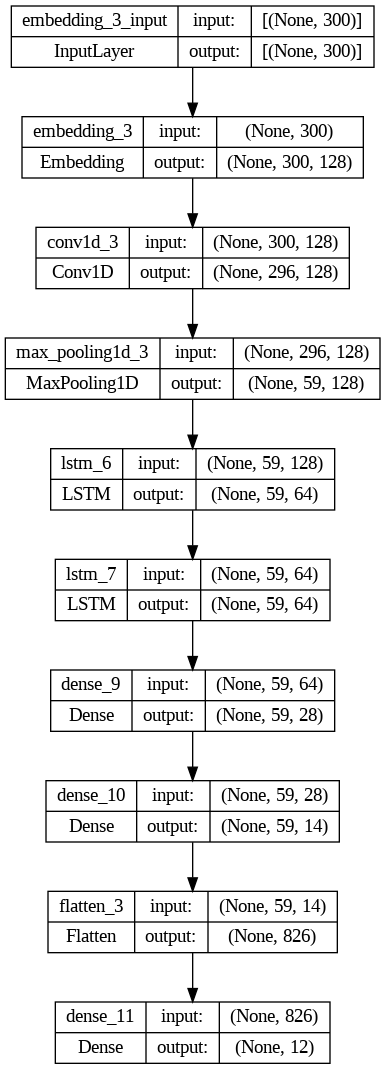

In [134]:
tf.keras.utils.plot_model(model, show_shapes=True)

In [135]:
# save the model

#tf.keras.models.save_model(model, file_path+'Document.h5', save_format='h5')
#model.save(path+'Document_Categorization.h5')

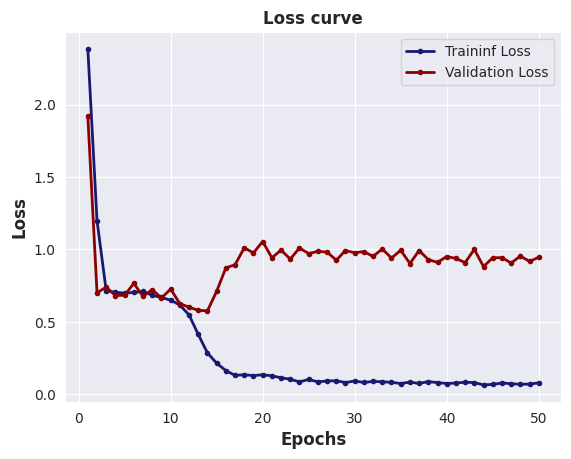

In [136]:
loss_values = history.history['loss']
val_loss_values = history.history['val_loss']
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(1, len(acc) + 1)
sns.set_style('darkgrid')


plt.plot(epochs, loss_values, color='midnightblue', linewidth = 2,
          marker='o', markersize=3,label='Training Accuracy')
plt.plot(epochs, val_loss_values, color='darkred', linewidth = 2,
          marker='o', markersize=3,label='Training Accuracy')
plt.title('Loss curve',fontsize=12,fontweight='bold')
plt.xlabel('Epochs',fontsize=12,fontweight='bold')
plt.ylabel('Loss',fontsize=12,fontweight='bold')
plt.legend(['Traininf Loss','Validation Loss'])


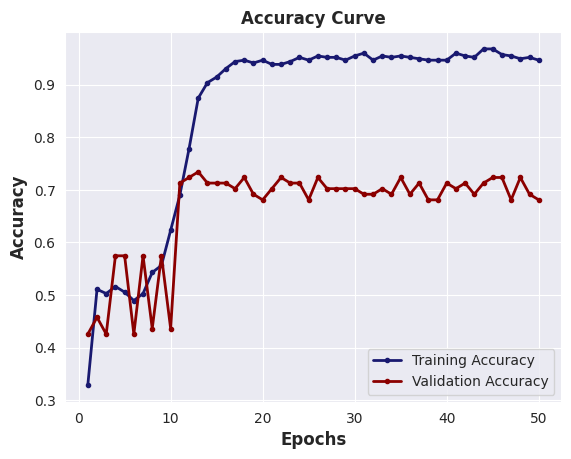

In [137]:
                  #=========================================================
                  ############### Epochs vs Validation Accuracy Plot ##########
                  #==========================================================

plt.plot(epochs, acc, color='midnightblue', linewidth = 2,
          marker='o', markersize=3,label='Training Accuracy')
plt.plot(epochs, val_acc, color='darkred', linewidth = 2,
          marker='o', markersize=3,label='Training Accuracy')
plt.title('Accuracy Curve',fontsize=12,fontweight='bold')
plt.xlabel('Epochs',fontsize=12,fontweight='bold')
plt.ylabel('Accuracy',fontsize=12,fontweight='bold')
plt.legend(['Training Accuracy','Validation Accuracy'])

# Model Performance on Test **Set**

In [138]:
class_names = ['Fraud','Partial Fraud']
predictions = model.predict(X_test)
y_pred = np.argmax(predictions, axis=1)
report = pd.DataFrame(classification_report(y_true = y_test, y_pred = y_pred, output_dict=True)).transpose()
report = report.rename(index={'0': 'Fraud','1':'Partial Fraud',})
report[['precision','recall','f1-score']]=report[['precision','recall','f1-score']].apply(lambda x: round(x*100,2))
report

2/2 [==============================] - 1s 39ms/step


,precision,recall,f1-score,support
Fraud,65.62,91.30,76.36,23.00
Partial Fraud,90.00,62.07,73.47,29.00
accuracy,75.00,75.00,75.00,0.75
macro avg,77.81,76.69,74.92,52.00
weighted avg,79.22,75.00,74.75,52.00


# Confusion **Matrix**

2/2 [==============================] - 0s 36ms/step


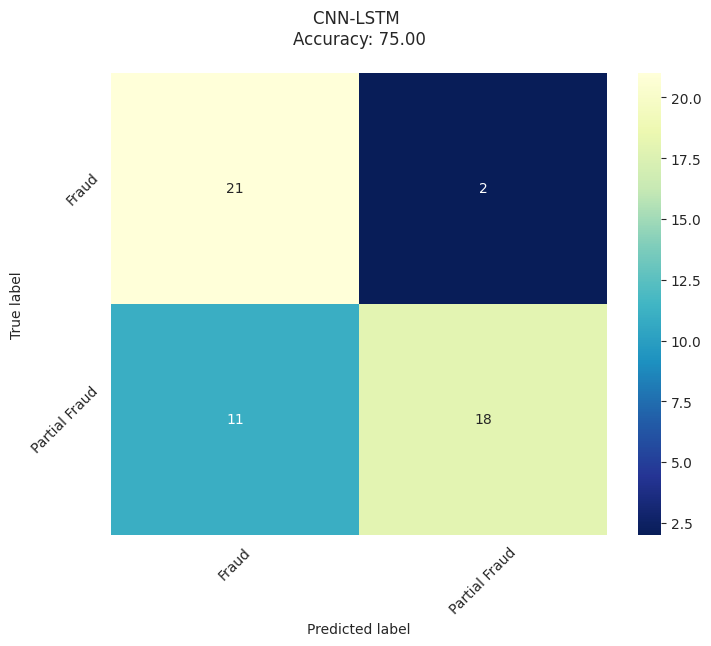

In [139]:
from sklearn.metrics import classification_report, confusion_matrix
predictions = model.predict(X_test)
y_pred = np.argmax(predictions, axis=1)

cm = confusion_matrix(y_test, y_pred)

class_names = ['Fraud','Partial Fraud']
# Transform to df for easier plotting
cm_df = pd.DataFrame(cm,
                     index = class_names,
                     columns = class_names)

plt.figure(figsize=(8,6))
sns.heatmap(cm_df, annot=True,cmap="YlGnBu_r", fmt='g')
plt.title('CNN-LSTM \nAccuracy: {0:.2f}\n'.format(accuracy_score(y_test, y_pred)*100))
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.xticks(rotation = 45)
plt.yticks(rotation = 45)
plt.show()

# Test with our own comments**

In [140]:
sample_comment = 'আমার থেকে ১৫ হাজার টাকা নিয়েছে আমি এ বিষয় গুলো জানতাম না তাই বুঝতে পারিনি।কিছুই করতে পারলাম না আমি ওদের বিরুদ্ধে'
cleaned_comment = process_comments(sample_comment)

class_names = ['Fraud','Partial Fraud']

# load the saved tokenizer
with open(file_path+'tokenizer.pickle', 'rb') as handle:
    loaded_tokenizer = pickle.load(handle)
#print(len(loaded_tokenizer.word_index))
seq= loaded_tokenizer.texts_to_sequences([cleaned_comment])
padded = pad_sequences(seq, value=0.0,padding='post', maxlen= 300 )
pred = model.predict(padded)
#print(pred)
class_names[np.argmax(pred)]


1/1 [==============================] - 0s 28ms/step


'Fraud'